# Delaunay-Watershed in 2D: compressing separated cells

This notebook compresses a 2-D mask of cells separated by medium (the repository's `mask_Cells_8.tif`, 68 cells), which is how a segmentation of nuclei looks, into its mesh and seeds, saves it, and rebuilds the mask from it.

The same steps apply to a segmentation of nuclei, for example the training images of the 2018 Data Science Bowl distributed with StarDist (`https://github.com/stardist/stardist/releases/download/0.1.0/dsb2018.zip`, not included here): read one of its masks with `tifffile.imread` in place of the mask below.

The compressed segmentation is the mesh's points and segments with one seed point per cell: from it the mask is rebuilt, each cell filling the region its seed lies in. Run the notebook from its folder, `Examples/two_dimensional/`, with `delaunay-watershed[viewing]` installed (matplotlib, for the figures).

## 1) Mesh the mask

In [1]:
import tifffile
from skimage.segmentation import expand_labels

import dw2d

image = tifffile.imread("../../data/two_dimensional/BW_images/CellCells_8.tif")
mask = tifffile.imread("../../data/two_dimensional/Masks/mask_Cells_8.tif")
import warnings

print("mask", mask.shape, mask.dtype, len(set(mask.ravel().tolist()) - {0}), "cells")

algorithm = (
    dw2d.MeshReconstructionAlgorithmFactory()
    .set_peak_local_points_placement_method(min_distance=3)
    .make_algorithm()
)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    points, segments, labels = algorithm.construct_mesh_from_segmentation_mask(mask)
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message)[:400]} ...")
print(f"{len(points)} points, {len(segments)} edges; sides padded: {algorithm.medium_margin_padding}")

mask (307, 338) uint8 68 cells


2686 points, 1895 edges; sides padded: {}


Cells of this mask reach every side of the image, so each side is a crop and none is padded (`algorithm.medium_margin_padding` is empty). `ThinMediumMarginWarning` names the cells that lie on a side with 1 or 2 pixels of medium between them and it: their mesh may include that medium, which the comparison below shows along the image border.

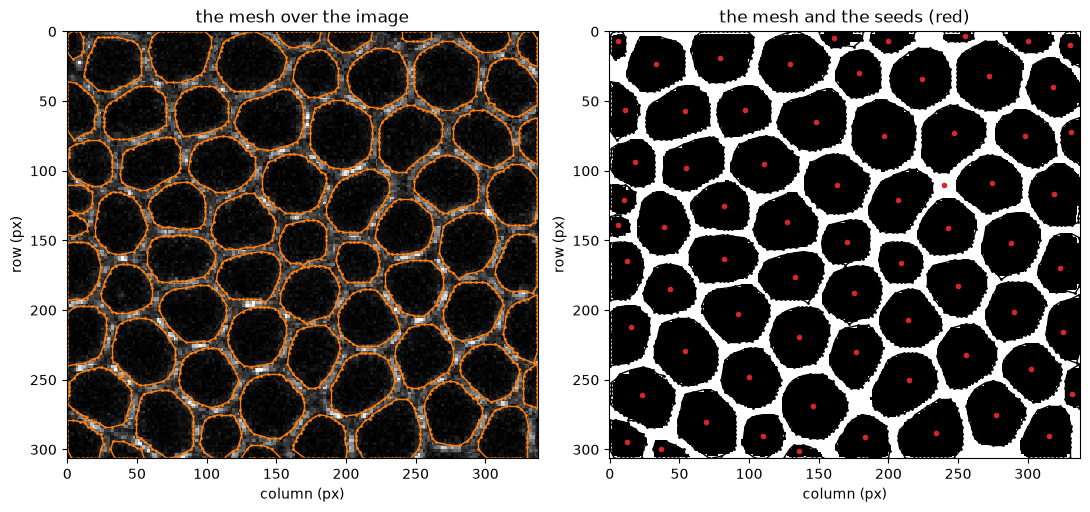

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection


def draw_mesh(ax, background, points, segments, colour="tab:orange", cmap="gray"):
    """Draw a 2-D mesh over an image, as imshow shows the image: column to the right, row down."""
    ax.imshow(background, cmap=cmap, interpolation="nearest")
    xy = points[:, ::-1]  # the mesh is in (row, column); matplotlib draws (x, y) = (column, row)
    ax.add_collection(LineCollection(xy[segments], colors=colour, linewidths=1))
    used = np.unique(segments)
    ax.plot(xy[used, 0], xy[used, 1], ".", color=colour, markersize=2)
    ax.set_xlabel("column (px)")
    ax.set_ylabel("row (px)")


fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
draw_mesh(axes[0], image, points, segments)
axes[0].set_title("the mesh over the image")
compressed = algorithm.last_compressed_segmentation
draw_mesh(axes[1], mask > 0, points, segments, colour="black", cmap="Greys")
seeds = np.asarray(compressed["seeds"])
axes[1].plot(seeds[:, 1], seeds[:, 0], "o", color="tab:red", markersize=3)
axes[1].set_title("the mesh and the seeds (red)")
plt.tight_layout()
plt.show()

## 2) Save the compressed segmentation and rebuild the mask

`last_compressed_segmentation` is a dictionary (`points`, `segments`, `labels`, `seeds`, `image_shape`, `image_border_vertices`). `dw2d.save_compressed_segmentation` saves it with `numpy.save`; `dw2d.reconstruct_mask_from_saved_file_dict` reads it and rebuilds the mask (`dw2d.reconstruct_mask_from_dict` does the same from the dictionary itself). Seed `k` fills label `k`.

In [3]:
print(sorted(compressed))
dw2d.save_compressed_segmentation("compressed_segmentation", compressed)  # numpy adds .npy
rebuilt = dw2d.reconstruct_mask_from_saved_file_dict("compressed_segmentation.npy")
print("rebuilt mask", rebuilt.shape, rebuilt.dtype)

['image_border_vertices', 'image_shape', 'labels', 'points', 'seeds', 'segments']
rebuilt mask (307, 338) int64


pixels with the mask's label: 96.69 %


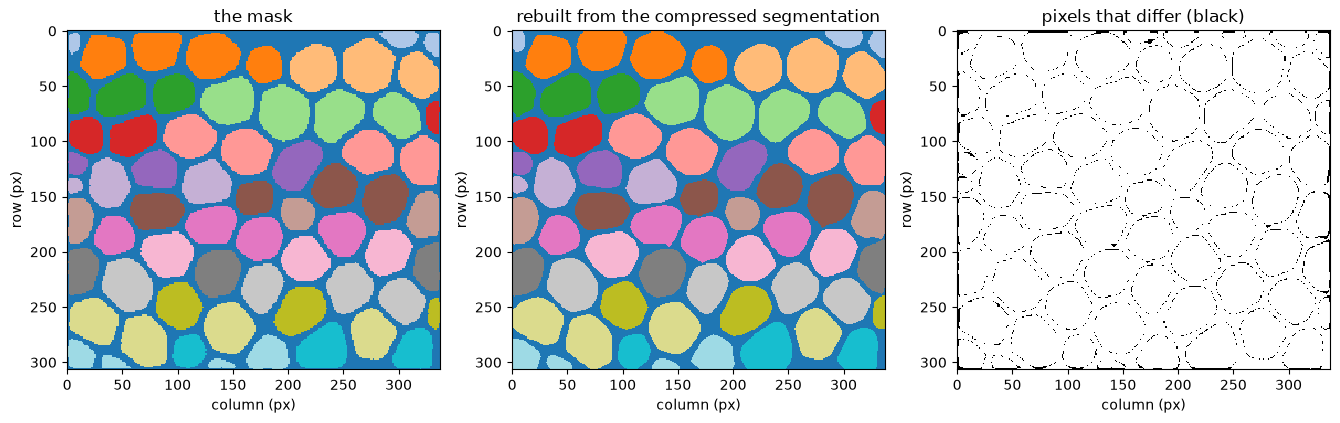

In [4]:
# The rebuilt labels are the seeds' indices: map each to the mask label it covers most, then compare pixel by pixel.
mapping = {}
for k in np.unique(rebuilt):
    values, counts = np.unique(mask[rebuilt == k], return_counts=True)
    mapping[int(k)] = int(values[np.argmax(counts)])
rebuilt_in_mask_labels = np.vectorize(mapping.get)(rebuilt)
agreement = (rebuilt_in_mask_labels == mask).mean()
print(f"pixels with the mask's label: {100 * agreement:.2f} %")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
axes[0].imshow(mask, cmap="tab20", interpolation="nearest")
axes[0].set_title("the mask")
axes[1].imshow(rebuilt_in_mask_labels, cmap="tab20", interpolation="nearest")
axes[1].set_title("rebuilt from the compressed segmentation")
axes[2].imshow(rebuilt_in_mask_labels != mask, cmap="Greys", interpolation="nearest")
axes[2].set_title("pixels that differ (black)")
for ax in axes:
    ax.set_xlabel("column (px)")
    ax.set_ylabel("row (px)")
plt.tight_layout()
plt.show()

## 3) The size saved

In [5]:
compressed_bytes = sum(np.asarray(compressed[key]).nbytes for key in ("points", "segments", "labels", "seeds", "image_shape"))
print("compressed segmentation:", compressed_bytes, "bytes")
print("mask as int64:", rebuilt.nbytes, "bytes")
print(f"relative size: {compressed_bytes / rebuilt.nbytes:.3f}")

compressed segmentation: 104736 bytes
mask as int64: 830128 bytes
relative size: 0.126
